# Interest-Rate Carry, Combined with the Optimal Long-Short Framework

This notebook fuses the **interest-rate carry strategies** (deposit-and-borrow carry, leveraged
staking) with the **semi-analytic optimal long-short framework** of `optimal_long_short.tex`.

**The one idea that makes it work.** The paper prices a leveraged long-short book from spot
prices and treats borrow/supply interest as out of scope. Under a rate held *deterministic* over
the horizon, carry enters the health-factor dynamics as a **per-leg price-growth drift shift**

$$\mu_1 \mapsto \mu_1 + r_{\text{supply}} \quad(\text{collateral / long leg}),\qquad
  \mu_2 \mapsto \mu_2 + r_{\text{borrow}} \quad(\text{debt / short leg}),$$

because `KouParams.mu_i` is defined so that $\mathbb{E}[e^{X_{i,t}}] = e^{\mu_i t}$. The net carry
$c = r_s - r_b$ lands *exactly* in the drift of the log-ratio $Z = X_1 - X_2$ (the barrier process)
**and** in the terminal payoff accrual — one substitution, both channels, closed form untouched.

**How this sits next to the paper.** The books below are *illustrative* (stylised parameters from
`job_runners.carry_frontier.demo_pairs`), chosen to show the mechanism. On the calibrated Aave v3
cross-section the paper finds deterministic carry **inert** for every volatile pair: it is worth at
most about $0.03$ barrier standard deviations over a month (paper Appendix D.2, Table 12), and even the
regime-switching version moves monthly survival by at most $0.09$ pp (Appendix D.3, Table 13).

Everything here is driven by `optimal_long_short.carry` (`apply_carry`, `optimal_carry_h0`,
`size_for_target_pliq`, `depeg_scenario`) on top of the existing Laplace-resolvent moment engine.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

# Repository root: the nearest ancestor holding pyproject.toml (works from any checkout).
ROOT = next(d for d in (Path.cwd(), *Path.cwd().parents) if (d / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from optimal_long_short.model.model_params import KouParams
from optimal_long_short.model.drift_service import drift_summary
from optimal_long_short import (CarryLeg, CarrySpec, apply_carry, optimal_carry_h0,
                                size_for_target_pliq, depeg_scenario, objective_phi)
from optimal_long_short.model.risk_report import h0_liquidation_moment_report
from jobs.carry_frontier import demo_pairs, frontier, build_metrics, TARGET_PLIQ

plt.rcParams.update({"font.family": "serif", "figure.dpi": 110, "font.size": 9})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 1. Carry is an effective drift — verify the identity

The claim is that `apply_carry` is *exactly* the substitution $\mu_i \mapsto \mu_i + r_i$, so the
net carry appears in the $Z$-drift to machine precision. We check both.

In [2]:
p = KouParams(mu1=0.487, sigma1=0.24, lam1=1.5, p1=0.5, eta1_pos=0.06, eta1_neg=0.06,
              mu2=1.20, sigma2=0.31, lam2=1.5, p2=0.5, eta2_pos=0.06, eta2_neg=0.06, rho=0.86)
spec = CarrySpec(CarryLeg("USDC", 0.0498), CarryLeg("WETH", 0.0286))
pc = apply_carry(p, spec)

print(f"net carry c = r_s - r_b = {spec.net_carry:+.4f}")
print(f"mu1: {p.mu1:.4f} -> {pc.mu1:.4f}   (+{pc.mu1 - p.mu1:.4f} = r_supply)")
print(f"mu2: {p.mu2:.4f} -> {pc.mu2:.4f}   (+{pc.mu2 - p.mu2:.4f} = r_borrow)")
dZ = (pc.muX1 - pc.muX2) - (p.muX1 - p.muX2)
print(f"change in Z-drift (muX1-muX2): {dZ:+.6f}   vs net carry {spec.net_carry:+.6f}")
assert abs(dZ - spec.net_carry) < 1e-12, "net carry must enter Z drift exactly"
print("\nIDENTITY HOLDS: carry = per-leg drift shift, net carry enters the barrier drift exactly.")

net carry c = r_s - r_b = +0.0212
mu1: 0.4870 -> 0.5368   (+0.0498 = r_supply)
mu2: 1.2000 -> 1.2286   (+0.0286 = r_borrow)
change in Z-drift (muX1-muX2): +0.021200   vs net carry +0.021200

IDENTITY HOLDS: carry = per-leg drift shift, net carry enters the barrier drift exactly.


## 2. Two data-grounded carry books

Both books use illustrative Kou parameters anchored to AAVE v3 Ethereum data (see
`job_runners/carry_frontier.py`):

| Book | legs | net carry | note |
|---|---|---|---|
| **USDC/WETH carry** | independent | **+2.12%** | USDC supply 4.98% − WETH borrow 2.86%; WETH vol 0.70 |
| **stETH/ETH staking** | $\rho=0.99$ | **+1.30%** | stETH staking+supply 3.8% − ETH borrow 2.5% |

We size each with the paper's rule (Conclusion): pick a max liquidation probability
$p_{\text{liq}}^\dagger = 10\%$ and invert $p_{\text{liq}}(h_0)$ for the operating cushion.

In [3]:
pairs = demo_pairs()
metrics = build_metrics(pairs)
rows = []
for name, m in metrics.items():
    for tag in ("no_carry", "carry"):
        d = m[tag]
        rows.append({"book": name, "carry": tag, "net_carry": m["net_carry"],
                     "H0*": d["H0"], "L0*": d["initial_leverage"],
                     "E[Pi|surv]": d["conditional_mean"], "cond_Sharpe": d["conditional_sharpe"]})
table = pd.DataFrame(rows)
table

,book,carry,net_carry,H0*,L0*,E[Pi|surv],cond_Sharpe
0,USDC/WETH carry,no_carry,0.0118,1.5469,2.0171,1.0710,4.6172
1,USDC/WETH carry,carry,0.0118,1.5434,2.0217,1.0840,4.6213
2,stETH/ETH staking,no_carry,0.0049,1.0705,4.1098,1.0849,2.1845
3,stETH/ETH staking,carry,0.0049,1.0701,4.1142,1.0890,2.1849


**Reading it.** Correlation, not carry, sets the affordable leverage: the near-collinear
stETH/ETH pair tolerates ~3.8× at 10% liquidation risk; the independent USDC/WETH pair caps near
~1.95×. Carry shifts the frontier favourably but modestly at these horizons — slightly more
leverage at the same risk, higher conditional mean.

## 3. Carry-adjusted frontier

$p_{\text{liq}}(L_0)$ and the penalised objective $\Phi(L_0)$, with and without carry.

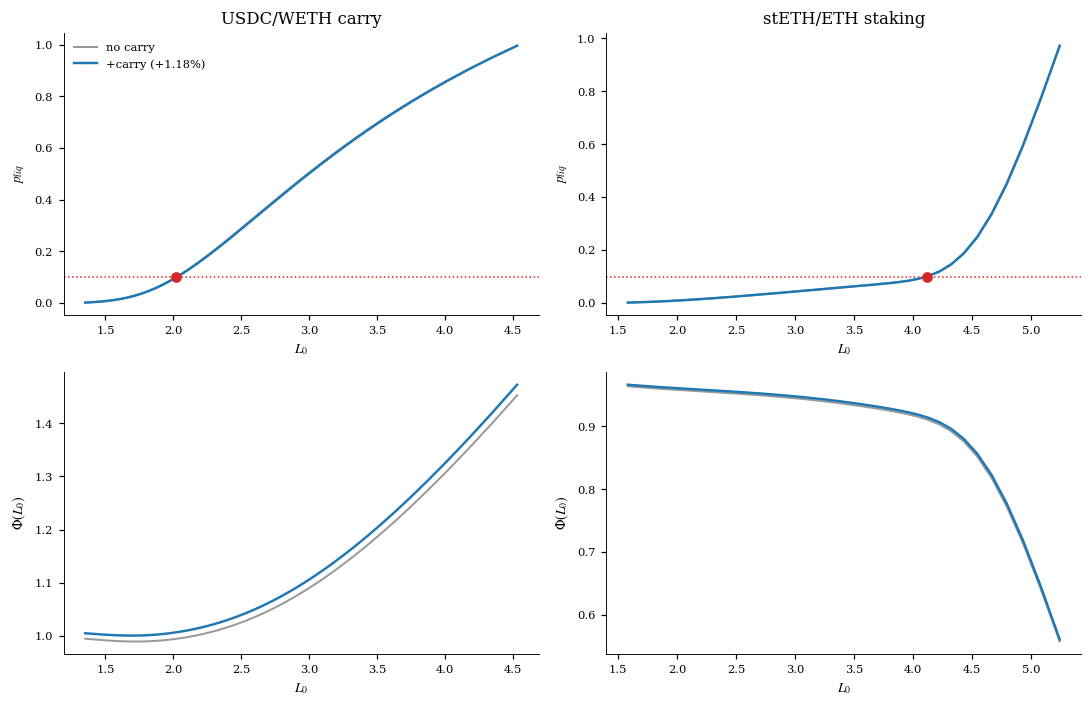

In [4]:
fig, axes = plt.subplots(2, len(pairs), figsize=(10, 6.5))
for j, pair in enumerate(pairs):
    f0, f1 = frontier(pair, carry=False), frontier(pair, carry=True)
    pt = size_for_target_pliq(pair.params, pair.spec, TARGET_PLIQ, b=pair.b, T=pair.T)
    ax = axes[0, j]
    ax.plot(f0["L0"], f0["p_liq"], color="0.6", lw=1.3, label="no carry")
    ax.plot(f1["L0"], f1["p_liq"], color="C0", lw=1.6, label=f"+carry ({pair.spec.net_carry:+.2%})")
    ax.axhline(TARGET_PLIQ, color="C3", ls=":", lw=1)
    ax.scatter([pt["initial_leverage"]], [pt["p_liq"]], color="C3", zorder=5)
    ax.set_title(pair.name); ax.set_xlabel("$L_0$"); ax.set_ylabel("$p_{liq}$")
    if j == 0: ax.legend()
    ax = axes[1, j]
    ax.plot(f0["L0"], f0["phi"], color="0.6", lw=1.3)
    ax.plot(f1["L0"], f1["phi"], color="C0", lw=1.6)
    ax.set_xlabel("$L_0$"); ax.set_ylabel(r"$\Phi(L_0)$")
fig.tight_layout(); plt.show()

## 4. Collateral-depeg sensitivity (scenario overlay)

A depeg haircut $d$ scales the health factor by $(1-d)$, i.e. holds the *same* book at cushion
$h_0 + \log(1-d)$. This is a scenario overlay — the base Kou dynamics stay the pure price model.
The leverage that correlation makes affordable is exactly what makes a book depeg-fragile.

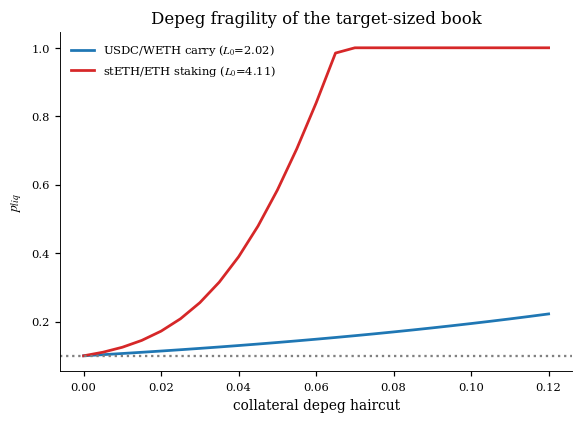

USDC/WETH carry 0%->p_liq 0.100 2%->p_liq 0.114 5%->p_liq 0.139 10%->p_liq 0.194


stETH/ETH staking 0%->p_liq 0.100 2%->p_liq 0.172 5%->p_liq 0.584 10%->p_liq 1.000


In [5]:
haircuts = np.linspace(0.0, 0.12, 25)
fig, ax = plt.subplots(figsize=(6, 4))
for pair, c in zip(pairs, ["C0", "C3"]):
    pt = size_for_target_pliq(pair.params, pair.spec, TARGET_PLIQ, b=pair.b, T=pair.T)
    dp = depeg_scenario(pair.params, pair.spec, pt["h0"], haircuts, b=pair.b, T=pair.T)
    ax.plot([r["depeg_fraction"] for r in dp], [r["p_liq"] for r in dp],
            color=c, lw=1.8, label=f"{pair.name} ($L_0$={pt['initial_leverage']:.2f})")
ax.axhline(TARGET_PLIQ, color="0.5", ls=":")
ax.set_xlabel("collateral depeg haircut"); ax.set_ylabel("$p_{liq}$")
ax.set_title("Depeg fragility of the target-sized book"); ax.legend(); plt.show()

for pair in pairs:
    pt = size_for_target_pliq(pair.params, pair.spec, TARGET_PLIQ, b=pair.b, T=pair.T)
    dp = depeg_scenario(pair.params, pair.spec, pt["h0"], [0.0, 0.02, 0.05, 0.10], b=pair.b, T=pair.T)
    print(pair.name, " ".join(f"{r['depeg_fraction']:.0%}->p_liq {r['p_liq']:.3f}" for r in dp))

## 5. Benchmark vs the empirical interest-rate strategies

The model-based **optimal-$h_0$ carry** is the semi-analytic strategy. The other interest-rate
strategies — **carry**, **supply-only**, and the **Taleb barbell** — remain *empirical* backtests;
here we load their out-of-sample walk-forward P&L (`walk_forward_oos_results.csv`) and score them on
common risk-adjusted metrics. (Momentum rotation lives in the benchmark notebook
`strategies/ccaave_v3_carry_trade_analysis.ipynb` §15.) The walk-forward file sits in
`optimal_long_short/strategy/`; no script in the repository regenerates it, so treat it as a stored input.

In [6]:
wf = pd.read_csv(ROOT / "optimal_long_short" / "strategy" / "walk_forward_oos_results.csv",
                 parse_dates=["entry_date"])

def score(pnl, liq=None, capital=100_000.0):
    pnl = np.asarray(pnl, float)
    r = pnl / capital
    ann = np.sqrt(len(r) / ((wf['entry_date'].iloc[-1]-wf['entry_date'].iloc[0]).days/365))
    sharpe = (r.mean() / r.std() * ann) if r.std() > 0 else np.nan
    downside = r[r < 0]
    sortino = (r.mean() / downside.std() * ann) if len(downside) and downside.std() > 0 else np.nan
    curve = np.cumsum(pnl)
    dd = (np.maximum.accumulate(curve) - curve)
    maxdd = dd.max()
    calmar = (pnl.sum() / maxdd) if maxdd > 0 else np.nan
    cvar95 = -np.mean(np.sort(r)[:max(1, int(0.05*len(r)))])
    out = {"total_pnl": pnl.sum(), "hit_rate": (pnl > 0).mean(), "Sharpe": sharpe,
           "Sortino": sortino, "max_drawdown": maxdd, "Calmar": calmar, "CVaR95": cvar95}
    if liq is not None:
        out["liq_freq"] = np.asarray(liq).mean()
    return out

bench = pd.DataFrame({
    "carry (empirical)":   score(wf["carry_pnl"], wf["carry_liq"]),
    "supply-only":         score(wf["supply_pnl"]),
    "barbell (Taleb)":     score(wf["barbell_pnl"], wf["barbell_agg_liq"]),
}).T
bench

,total_pnl,hit_rate,Sharpe,Sortino,max_drawdown,Calmar,CVaR95,liq_freq
carry (empirical),"-86,295.8896",0.5263,-0.6092,-0.9449,"124,157.2129",-0.6951,0.4064,0.2105
supply-only,"25,258.9775",1.0000,7.4705,NaN,0.0000,NaN,-0.0068,NaN
barbell (Taleb),"17,603.0998",0.5263,1.4377,7.0485,"3,066.2040",5.7410,0.0133,0.5789


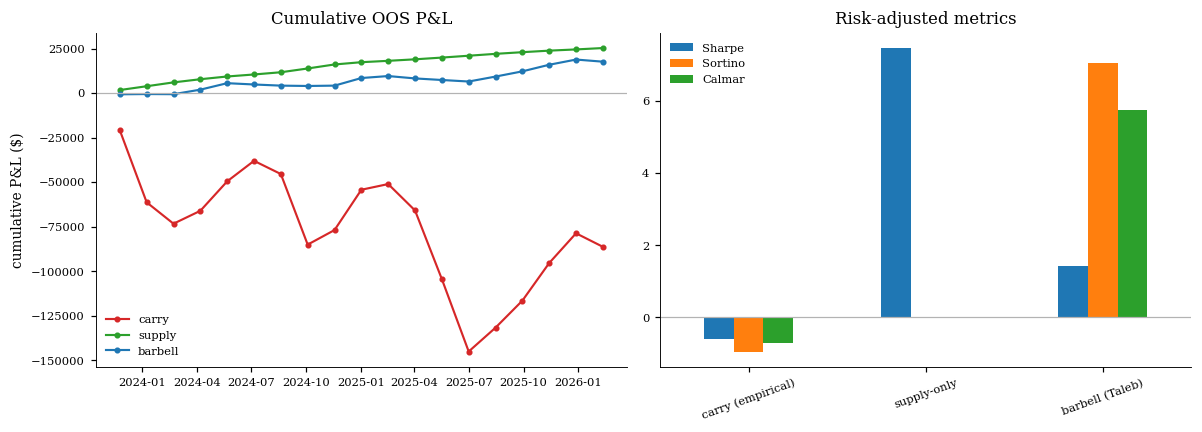

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for col, c in zip(["carry_pnl", "supply_pnl", "barbell_pnl"], ["C3", "C2", "C0"]):
    ax[0].plot(wf["entry_date"], np.cumsum(wf[col]), marker="o", ms=3, lw=1.4,
               color=c, label=col.replace("_pnl", ""))
ax[0].axhline(0, color="0.7", lw=0.8); ax[0].set_title("Cumulative OOS P&L"); ax[0].legend()
ax[0].set_ylabel("cumulative P&L ($)")
bench[["Sharpe", "Sortino", "Calmar"]].plot.bar(ax=ax[1])
ax[1].set_title("Risk-adjusted metrics"); ax[1].axhline(0, color="0.7", lw=0.8)
ax[1].tick_params(axis="x", rotation=20)
fig.tight_layout(); plt.show()

**Takeaway.** Over the walk-forward window the empirical carry *loses* money (about $-86$k total,
Sharpe $-0.6$), is liquidated in about one period in five, and carries by far the deepest drawdown.
Supply-only is small but never loses. The barbell ends positive with a shallow drawdown, even
though its levered sleeve is flagged liquidated in more than half the periods (`barbell_agg_liq`).
The semi-analytic layer adds what the backtests cannot: an *ex-ante*, closed-form liquidation
probability for any chosen cushion $h_0$ — the same $p_{\text{liq}}$ that the walk-forward
`pred_liq_prob` column only estimates by simulation. It does not say that leverage *pays*: in a
realised replay of all 37 Aave v3 pairs over 2023–2026 (paper §8.4), leverage beat the unlevered
position in only 4 pairs at 1.25× and lost through volatility drag and liquidations at higher
leverage, consistent with the losing carry book here.

## 6. Summary

- **Carry = drift shift.** Deterministic supply/borrow accrual enters the Kou / Laplace-resolvent
  framework as $\mu_1\mathrel{+}=r_s$, $\mu_2\mathrel{+}=r_b$ — verified to machine precision. The
  semi-analytic moments and survival probability apply verbatim (paper Appendix D.1, Prop. D.1).
- **On real pairs the tilt is negligible.** Calibrated across all 37 screened Aave v3 pairs,
  deterministic carry is worth at most ~0.03 barrier standard deviations per month for volatile
  pairs (paper Appendix D.2); the demo books here exaggerate it to make the mechanism visible.
- **Correlation sets leverage; carry tilts the frontier.** stETH/ETH tolerates ~3.8× at 10%
  liquidation risk; USDC/WETH caps near ~1.95×. Positive carry buys marginally more leverage at
  the same risk.
- **Depeg is the hidden tail.** The correlation-enabled leverage is exactly what makes a book
  depeg-fragile: a 10% stETH haircut is fatal at 3.8×; the 1.95× USDC book degrades gracefully.
- **Model + empirics are complementary.** The model supplies the closed-form $p_{\text{liq}}$ of
  a chosen cushion that the empirical carry / supply / barbell backtests can only simulate. Whether
  leverage pays is a separate question: the paper's break-even drift (§8.2) is small but cannot be
  estimated precisely, and realised leverage rarely paid across the 37 pairs (§8.4).

Reproduce the carry figures with `python jobs/carry_frontier.py` (`fig_carry_depeg.pdf` is used by
the slides; the paper no longer includes either carry figure).